Miniprojeto Semana 7


In [25]:
import pandas as pd
import numpy as np
import random
from datetime import datetime, timedelta

def gerar_dataset_vendas(n_registros=200, seed=42):
    """Gera um dataset sintetico de vendas com dados sujos."""
    random.seed(seed)
    np.random.seed(seed)

    produtos = ["Notebook", "Smartphone", "Tablet", "Monitor",
                "Teclado", "Mouse", "Headset"]
    categorias = {"Notebook": "Computadores", "Smartphone": "Celulares",
                  "Tablet": "Celulares", "Monitor": "Computadores",
                  "Teclado": "Perifericos", "Mouse": "Perifericos",
                  "Headset": "Perifericos"}
    precos = {"Notebook": 3500, "Smartphone": 2200, "Tablet": 1800,
              "Monitor": 1200, "Teclado": 250, "Mouse": 120,
              "Headset": 350}
    regioes = ["Sudeste", "Sul", "Nordeste", "Centro-Oeste", "Norte"]

    data_inicio = datetime(2025, 1, 1)
    dados = []

    for i in range(n_registros):
        produto = random.choice(produtos)
        categoria = categorias[produto]
        quantidade = random.randint(1, 10)
        preco = round(precos[produto] * random.uniform(0.85, 1.15), 2)
        data = data_inicio + timedelta(days=random.randint(0, 364))
        data_txt = data.strftime("%Y-%m-%d")
        cliente = f"Cliente_{random.randint(1, 50):03d}"

        # --- sujeira proposital para a etapa de limpeza ---
        if random.random() < 0.03:
        	data_txt = "DATA INVALIDA"       	# data invalida

        dados.append({
            "id_venda": i + 1,
            "data_venda": data_txt,
            "cliente": cliente,
            "produto": produto,
            "categoria": categoria,
            "regiao": random.choice(regioes),
            "quantidade": quantidade,
            "preco_unitario": preco,
        })

    return pd.DataFrame(dados)


# Gerar e salvar o CSV bruto
df_bruto = gerar_dataset_vendas()
df_bruto.to_csv("vendas.csv", index=False)
print(f"Dataset gerado com {len(df_bruto)} registros.")
print(df_bruto.head())


Dataset gerado com 200 registros.
   id_venda     data_venda      cliente     produto     categoria    regiao  \
0         1     2025-05-21  Cliente_016       Mouse   Perifericos   Sudeste   
1         2  DATA INVALIDA  Cliente_003       Mouse   Perifericos       Sul   
2         3     2025-10-15  Cliente_013  Smartphone     Celulares     Norte   
3         4     2025-05-23  Cliente_001     Monitor  Computadores       Sul   
4         5     2025-03-21  Cliente_014       Mouse   Perifericos  Nordeste   

   quantidade  preco_unitario  
0           2          102.90  
1           9          105.13  
2           9         2267.33  
3           4         1181.72  
4           7          114.25  


In [26]:
from google.colab import files
files.download("vendas.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:

def inspecionar_dados(df):
    """Exibe as informacoes estruturais do DataFrame."""
    print("\n=== INSPECAO INICIAL DO DATASET ===")
    print(f"Shape: {df.shape}")
    print(f"\nColunas: {list(df.columns)}")
    print(f"\nTipos de dados:\n{df.dtypes}")
    print(f"\nValores nulos por coluna:\n{df.isnull().sum()}")
    print(f"\nPrimeiros registros:\n{df.head()}")
    return df



In [28]:
inspecionar_dados(df_bruto)


=== INSPECAO INICIAL DO DATASET ===
Shape: (200, 8)

Colunas: ['id_venda', 'data_venda', 'cliente', 'produto', 'categoria', 'regiao', 'quantidade', 'preco_unitario']

Tipos de dados:
id_venda            int64
data_venda         object
cliente            object
produto            object
categoria          object
regiao             object
quantidade          int64
preco_unitario    float64
dtype: object

Valores nulos por coluna:
id_venda          0
data_venda        0
cliente           0
produto           0
categoria         0
regiao            0
quantidade        0
preco_unitario    0
dtype: int64

Primeiros registros:
   id_venda     data_venda      cliente     produto     categoria    regiao  \
0         1     2025-05-21  Cliente_016       Mouse   Perifericos   Sudeste   
1         2  DATA INVALIDA  Cliente_003       Mouse   Perifericos       Sul   
2         3     2025-10-15  Cliente_013  Smartphone     Celulares     Norte   
3         4     2025-05-23  Cliente_001     Monitor  Com

,id_venda,data_venda,cliente,produto,categoria,regiao,quantidade,preco_unitario
0,1,2025-05-21,Cliente_016,Mouse,Perifericos,Sudeste,2,102.90
1,2,DATA INVALIDA,Cliente_003,Mouse,Perifericos,Sul,9,105.13
2,3,2025-10-15,Cliente_013,Smartphone,Celulares,Norte,9,2267.33
3,4,2025-05-23,Cliente_001,Monitor,Computadores,Sul,4,1181.72
4,5,2025-03-21,Cliente_014,Mouse,Perifericos,Nordeste,7,114.25
...,...,...,...,...,...,...,...,...
195,196,2025-04-21,Cliente_028,Headset,Perifericos,Sul,9,373.19
196,197,2025-07-24,Cliente_027,Monitor,Computadores,Nordeste,6,1317.87
197,198,2025-07-11,Cliente_010,Monitor,Computadores,Centro-Oeste,6,1259.44
198,199,2025-02-17,Cliente_028,Notebook,Computadores,Nordeste,2,3848.36


In [29]:
def tratar_dados(df):
    """Trata o DataFrame de vendas e gera um relatorio de limpeza."""

    # 1. Guardar el total inicial y trabajar con una copia
    df_limpo = df.copy()
    registros_iniciais = len(df_limpo)

    # 2. Remova os espaços extras nas colunas de texto
    colunas_texto = df_limpo.select_dtypes(include=["object", "string"]).columns
    textos_ajustados = 0

    for coluna in colunas_texto:
        texto_original = df_limpo[coluna].copy()
        df_limpo[coluna] = df_limpo[coluna].str.strip()
        textos_ajustados += (
            texto_original.ne(df_limpo[coluna])
            & texto_original.notna()
        ).sum()

    # 3. Converter datas e remover as inválidas
    df_limpo["data_venda"] = pd.to_datetime(
        df_limpo["data_venda"], errors="coerce"
    )

    datas_invalidas = df_limpo["data_venda"].isna().sum()
    df_limpo = df_limpo.dropna(subset=["data_venda"]).copy()

    # 4. Ajustar os tipos numéricos
    quantidade_convertida = 0
    if df_limpo["quantidade"].dtype != "int64":
        quantidade_convertida = df_limpo["quantidade"].notna().sum()

    df_limpo["quantidade"] = pd.to_numeric(
        df_limpo["quantidade"], errors="raise"
    ).astype("int64")

    preco_convertido = 0
    if df_limpo["preco_unitario"].dtype != "float64":
        preco_convertido = df_limpo["preco_unitario"].notna().sum()

    df_limpo["preco_unitario"] = pd.to_numeric(
        df_limpo["preco_unitario"], errors="raise"
    ).astype("float64")

    # 5. Elaborar o relatório de limpeza
    registros_finais = len(df_limpo)

    relatorio = {
        "registros_iniciais": registros_iniciais,
        "textos_ajustados": int(textos_ajustados),
        "datas_invalidas_removidas": int(datas_invalidas),
        "quantidades_convertidas": int(quantidade_convertida),
        "precos_convertidos": int(preco_convertido),
        "registros_finais": registros_finais,
        "registros_removidos": registros_iniciais - registros_finais
    }

    print("\n=== RELATORIO DE LIMPEZA ===")
    for motivo, quantidade in relatorio.items():
        print(f"{motivo}: {quantidade}")

    return df_limpo, relatorio

In [30]:
df_limpo, relatorio = tratar_dados(df_bruto)


=== RELATORIO DE LIMPEZA ===
registros_iniciais: 200
textos_ajustados: 0
datas_invalidas_removidas: 6
quantidades_convertidas: 0
precos_convertidos: 0
registros_finais: 194
registros_removidos: 6


In [31]:
print(df_limpo.shape)
print(df_limpo.dtypes)
print(df_limpo["data_venda"].isna().sum())

(194, 8)
id_venda                   int64
data_venda        datetime64[ns]
cliente                   object
produto                   object
categoria                 object
regiao                    object
quantidade                 int64
preco_unitario           float64
dtype: object
0


In [32]:
def criar_colunas_derivadas(df):
    """Cria colunas derivadas a partir do dataset limpo."""

    # Trabalhar com uma cópia do dataset limpo
    df_derivado = df.copy()

    # 1. Receita total por venda: quantidade x preço unitário
    df_derivado["receita_total"] = (
        df_derivado["quantidade"] * df_derivado["preco_unitario"]
    )

    # 2. Mês numérico
    df_derivado["mes"] = df_derivado["data_venda"].dt.month

    # 3. Nome do mês em português
    meses = {
        1: "Janeiro",
        2: "Fevereiro",
        3: "Março",
        4: "Abril",
        5: "Maio",
        6: "Junho",
        7: "Julho",
        8: "Agosto",
        9: "Setembro",
        10: "Outubro",
        11: "Novembro",
        12: "Dezembro"
    }

    df_derivado["mes_nome"] = df_derivado["mes"].map(meses)

    # 4. Trimestre
    df_derivado["trimestre"] = (
        "Q" + df_derivado["data_venda"].dt.quarter.astype(str)
    )

    # 5. Ano
    df_derivado["ano"] = df_derivado["data_venda"].dt.year

    # 6. Classificação condicional da receita por item
    condicoes = [
        df_derivado["receita_total"] < 500,
        (df_derivado["receita_total"] >= 500)
        & (df_derivado["receita_total"] < 5000),
        df_derivado["receita_total"] >= 5000
    ]

    faixas = [
        "Baixo Valor",
        "Medio Valor",
        "Alto Valor"
    ]

    df_derivado["faixa_receita_item"] = "Nao Classificado"

    for condicao, faixa in zip(condicoes, faixas):
        df_derivado.loc[condicao, "faixa_receita_item"] = faixa

    # 7. Exibir o resultado
    print("\n=== DATASET COM COLUNAS DERIVADAS ===")
    print(f"Formato do dataset: {df_derivado.shape}")
    print("\nColunas:")
    print(list(df_derivado.columns))

    print("\nPrimeiros registros:")
    print(df_derivado.head().to_string(index=False))

    print("\nDistribuição por faixa de receita:")
    print(df_derivado["faixa_receita_item"].value_counts())

    # Retornar o dataset transformado
    return df_derivado


# Executar RF04 usando o dataset limpo do RF03
df_derivado = criar_colunas_derivadas(df_limpo)


=== DATASET COM COLUNAS DERIVADAS ===
Formato do dataset: (194, 14)

Colunas:
['id_venda', 'data_venda', 'cliente', 'produto', 'categoria', 'regiao', 'quantidade', 'preco_unitario', 'receita_total', 'mes', 'mes_nome', 'trimestre', 'ano', 'faixa_receita_item']

Primeiros registros:
 id_venda data_venda     cliente    produto    categoria   regiao  quantidade  preco_unitario  receita_total  mes mes_nome trimestre  ano faixa_receita_item
        1 2025-05-21 Cliente_016      Mouse  Perifericos  Sudeste           2          102.90         205.80    5     Maio        Q2 2025        Baixo Valor
        3 2025-10-15 Cliente_013 Smartphone    Celulares    Norte           9         2267.33       20405.97   10  Outubro        Q4 2025         Alto Valor
        4 2025-05-23 Cliente_001    Monitor Computadores      Sul           4         1181.72        4726.88    5     Maio        Q2 2025        Medio Valor
        5 2025-03-21 Cliente_014      Mouse  Perifericos Nordeste           7          11

In [33]:
def criar_colunas_derivadas(df):
    """Cria colunas derivadas a partir do dataset limpo."""

    # Cópia do dataset limpo
    df_derivado = df.copy()

    # Receita total por venda: quantidade x preço unitário
    df_derivado["receita_total"] = (
        df_derivado["quantidade"] * df_derivado["preco_unitario"]
    )

    # Mês numérico
    df_derivado["mes"] = df_derivado["data_venda"].dt.month

    # Nome do mês
    meses = {
        1: "Janeiro",
        2: "Fevereiro",
        3: "Março",
        4: "Abril",
        5: "Maio",
        6: "Junho",
        7: "Julho",
        8: "Agosto",
        9: "Setembro",
        10: "Outubro",
        11: "Novembro",
        12: "Dezembro"
    }

    df_derivado["mes_nome"] = df_derivado["mes"].map(meses)

    # Trimestre
    df_derivado["trimestre"] = (
        "Q" + df_derivado["data_venda"].dt.quarter.astype(str)
    )

    # Ano
    df_derivado["ano"] = df_derivado["data_venda"].dt.year

    # Classificação condicional da receita por item
    condicoes = [
        df_derivado["receita_total"] < 500,
        (df_derivado["receita_total"] >= 500)
        & (df_derivado["receita_total"] < 5000),
        df_derivado["receita_total"] >= 5000
    ]

    faixas = [
        "Baixo Valor",
        "Medio Valor",
        "Alto Valor"
    ]

    df_derivado["faixa_receita_item"] = "Nao Classificado"

    for condicao, faixa in zip(condicoes, faixas):
        df_derivado.loc[condicao, "faixa_receita_item"] = faixa

    # Exibir o resultado
    print("\n=== DATASET COM COLUNAS DERIVADAS ===")
    print(f"Formato do dataset: {df_derivado.shape}")
    print("\nColunas:")
    print(list(df_derivado.columns))

    print("\nPrimeiros registros:")
    print(df_derivado.head().to_string(index=False))

    print("\nDistribuição por faixa de receita:")
    print(df_derivado["faixa_receita_item"].value_counts())

    # Retornar o dataset transformado
    return df_derivado


# Executar usando o dataset limpo
df_derivado = criar_colunas_derivadas(df_limpo)


=== DATASET COM COLUNAS DERIVADAS ===
Formato do dataset: (194, 14)

Colunas:
['id_venda', 'data_venda', 'cliente', 'produto', 'categoria', 'regiao', 'quantidade', 'preco_unitario', 'receita_total', 'mes', 'mes_nome', 'trimestre', 'ano', 'faixa_receita_item']

Primeiros registros:
 id_venda data_venda     cliente    produto    categoria   regiao  quantidade  preco_unitario  receita_total  mes mes_nome trimestre  ano faixa_receita_item
        1 2025-05-21 Cliente_016      Mouse  Perifericos  Sudeste           2          102.90         205.80    5     Maio        Q2 2025        Baixo Valor
        3 2025-10-15 Cliente_013 Smartphone    Celulares    Norte           9         2267.33       20405.97   10  Outubro        Q4 2025         Alto Valor
        4 2025-05-23 Cliente_001    Monitor Computadores      Sul           4         1181.72        4726.88    5     Maio        Q2 2025        Medio Valor
        5 2025-03-21 Cliente_014      Mouse  Perifericos Nordeste           7          11

In [34]:

def calcular_metricas(df):
    """
    Calcula as metricas agregadas do dataset.
    Retorna um dicionario de DataFrames.
    """

    metricas = {}

    # Receita, quantidade vendida e número de vendas por mês
    metricas["por_mes"] = (
        df.groupby("mes")
        .agg(
            receita_total=("receita_total", "sum"),
            quantidade=("quantidade", "sum"),
            n_vendas=("id_venda", "count")
        )
        .reset_index()
        .sort_values("mes")
    )

    # Receita total por produto: Top 5
    metricas["top_produtos"] = (
        df.groupby("produto")
        .agg(receita_total=("receita_total", "sum"))
        .sort_values("receita_total", ascending=False)
        .head(5)
        .reset_index()
    )

    # Receita total por categoria
    metricas["por_categoria"] = (
        df.groupby("categoria")
        .agg(receita_total=("receita_total", "sum"))
        .sort_values("receita_total", ascending=False)
        .reset_index()
    )

    # Receita total e ticket médio por região
    metricas["por_regiao"] = (
        df.groupby("regiao")
        .agg(
            receita_total=("receita_total", "sum"),
            ticket_medio=("receita_total", "mean")
        )
        .sort_values("receita_total", ascending=False)
        .reset_index()
    )

    # Exibir todas as métricas no console
    print("\n=== POR MES ===")
    print(metricas["por_mes"].to_string(index=False))

    print("\n=== TOP PRODUTOS ===")
    print(metricas["top_produtos"].to_string(index=False))

    print("\n=== POR CATEGORIA ===")
    print(metricas["por_categoria"].to_string(index=False))

    print("\n=== POR REGIAO ===")
    print(metricas["por_regiao"].to_string(index=False))

    return metricas


# Executar a partir do dataset transformado
metricas = calcular_metricas(df_derivado)



=== POR MES ===
 mes  receita_total  quantidade  n_vendas
   1      121707.77          86        15
   2      186065.22          84        18
   3      129138.46          87        19
   4       68247.67          85        14
   5      103600.61          75        12
   6       72067.26          73        16
   7      129427.58          97        19
   8      156072.31         107        19
   9       57509.42          77        14
  10      181878.41         137        25
  11       89645.62          86        15
  12       84849.98          41         8

=== TOP PRODUTOS ===
   produto  receita_total
  Notebook      493242.63
Smartphone      343721.95
    Tablet      236519.71
   Monitor      205212.61
   Headset       48879.79

=== POR CATEGORIA ===
   categoria  receita_total
Computadores      698455.24
   Celulares      580241.66
 Perifericos      101513.41

=== POR REGIAO ===
      regiao  receita_total  ticket_medio
Centro-Oeste      342981.92   7297.487660
       Norte      30

In [35]:

def segmentar_clientes(df):
    """
    Agrupa por cliente, soma a receita e classifica em
    Bronze / Prata / Ouro.
    Retorna um DataFrame com cliente, total_gasto e segmento.
    """

    # Agrupar por cliente e somar o gasto total
    clientes = (
        df.groupby("cliente")
        .agg(total_gasto=("receita_total", "sum"))
        .reset_index()
    )

    # Classificar cada cliente com uma função lambda e apply()
    clientes["segmento"] = clientes["total_gasto"].apply(
        lambda gasto: (
            "Bronze" if gasto < 5000
            else "Prata" if gasto <= 15000
            else "Ouro"
        )
    )

    # Ordenar os clientes do maior gasto para o menor
    top_clientes = clientes.sort_values(
        "total_gasto", ascending=False
    ).head(10)

    # Exibir os 10 maiores clientes
    print("\n=== TOP 10 CLIENTES POR GASTO ===")
    print(top_clientes.to_string(index=False))

    # Exibir a distribuição de clientes por segmento
    print("\n=== DISTRIBUICAO POR SEGMENTO ===")
    print(clientes["segmento"].value_counts())

    # Retornar todos os clientes classificados
    return clientes


# Executar usando o dataset transformado
clientes_segmentados = segmentar_clientes(df_derivado)



=== TOP 10 CLIENTES POR GASTO ===
    cliente  total_gasto segmento
Cliente_049     86381.62     Ouro
Cliente_006     78524.09     Ouro
Cliente_009     72517.27     Ouro
Cliente_016     66606.02     Ouro
Cliente_008     58695.74     Ouro
Cliente_020     54182.88     Ouro
Cliente_044     54128.61     Ouro
Cliente_028     51710.71     Ouro
Cliente_038     44741.97     Ouro
Cliente_035     43323.63     Ouro

=== DISTRIBUICAO POR SEGMENTO ===
segmento
Ouro      35
Prata      9
Bronze     5
Name: count, dtype: int64


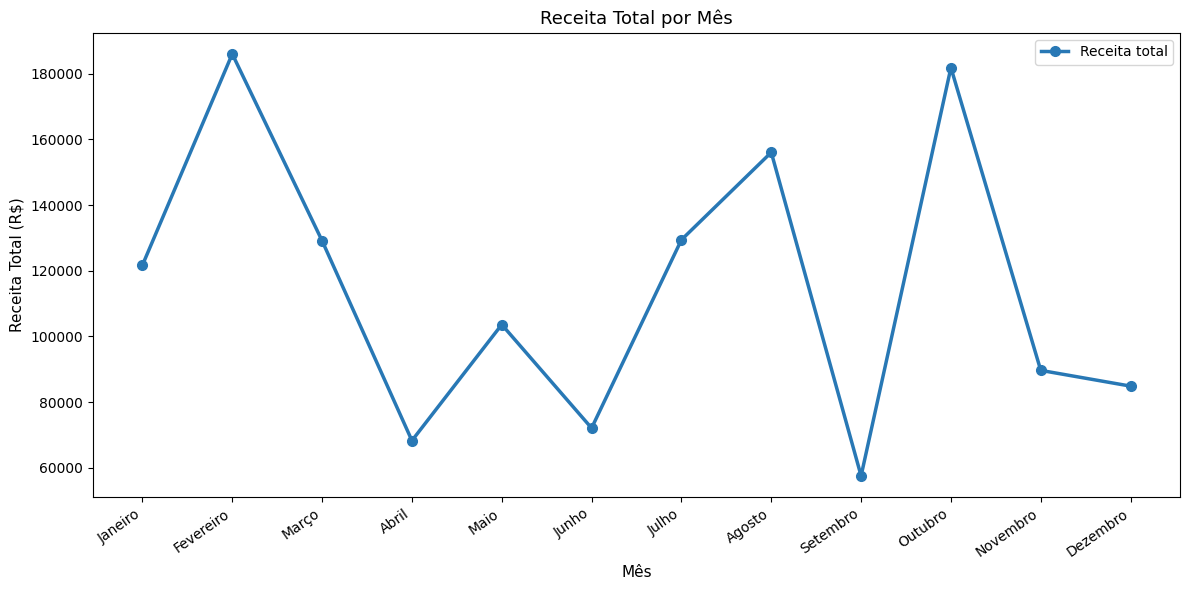

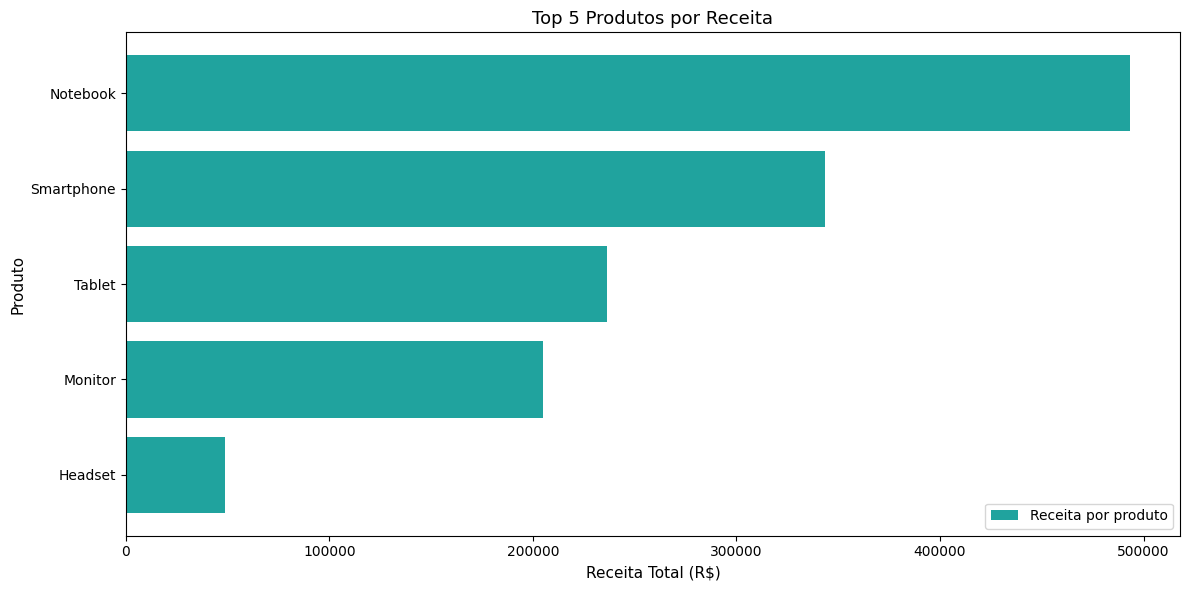

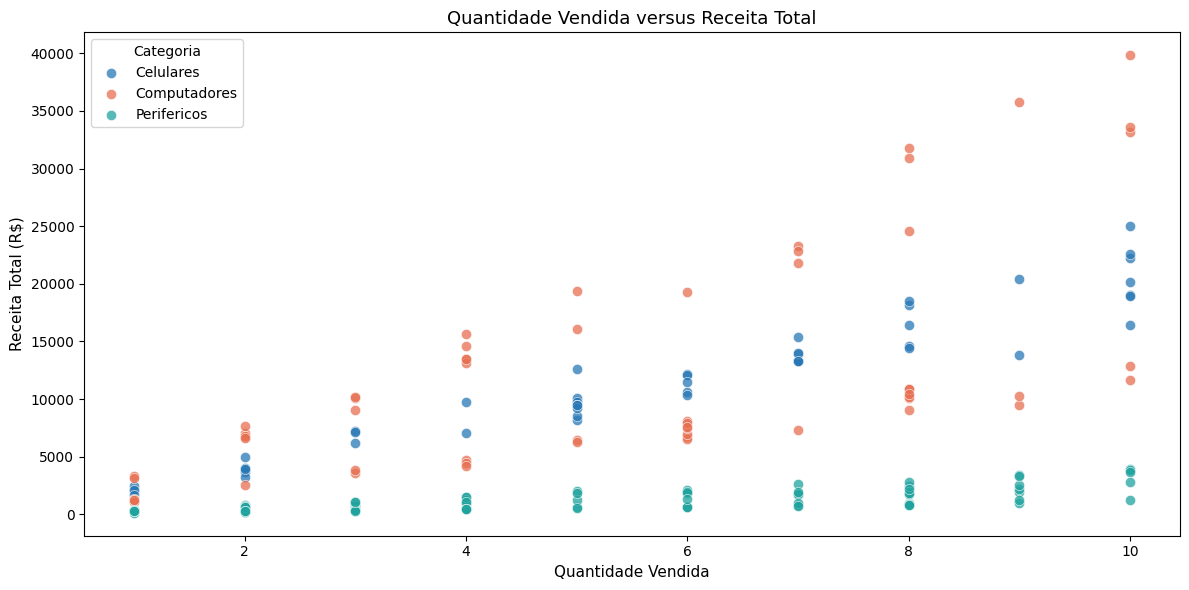

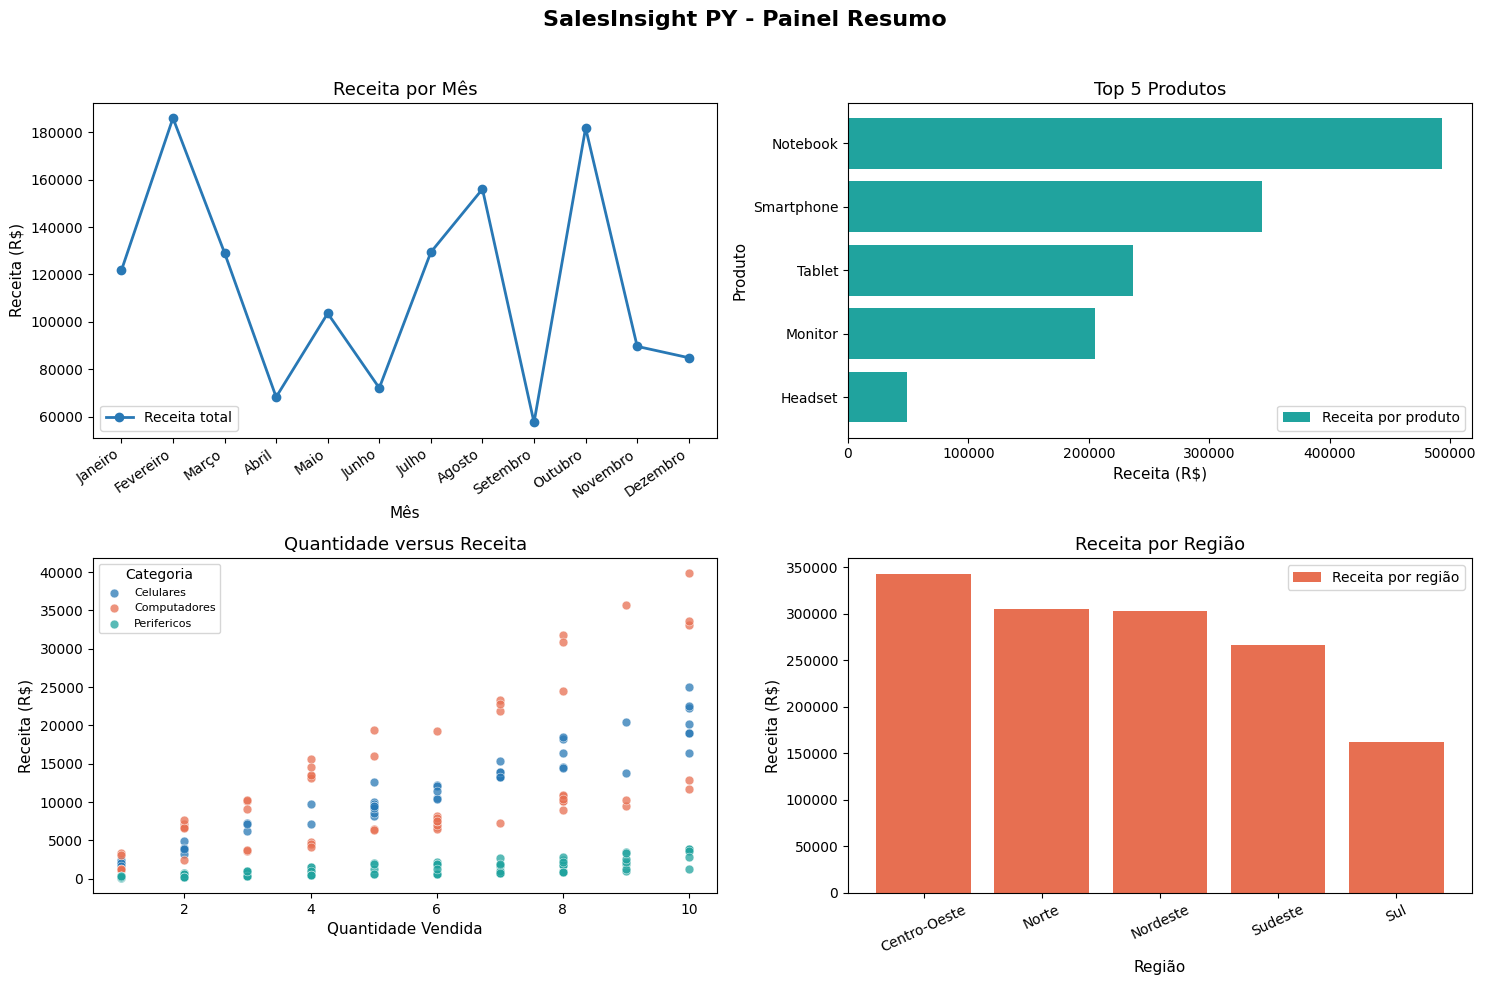


=== ARQUIVOS GERADOS ===
1. outputs/graficos/receita_por_mes.png
2. outputs/graficos/top_produtos.png
3. outputs/graficos/quantidade_vs_receita.png
4. outputs/graficos/painel_resumo.png

Total: 4 gráficos PNG gerados com sucesso.


In [36]:

import matplotlib.pyplot as plt
import os

# Configuração visual
PALETA = {
    "azul": "#2878B5",
    "turquesa": "#20A39E",
    "coral": "#E76F51",
    "dourado": "#E9C46A",
    "roxo": "#8064A2",
    "verde": "#4C956C",
    "cinza": "#59636E"
}

CORES_CATEGORIAS = [
    PALETA["azul"],
    PALETA["coral"],
    PALETA["turquesa"],
    PALETA["roxo"],
    PALETA["verde"],
    PALETA["dourado"]
]

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# Criar a pasta para salvar os gráficos
os.makedirs("outputs/graficos", exist_ok=True)

# Recuperar as métricas calculadas no RF05
por_mes = metricas["por_mes"]
top_produtos = metricas["top_produtos"]
por_regiao = metricas["por_regiao"]

# Criar nomes dos meses em português para os eixos
nomes_meses = {
    1: "Janeiro", 2: "Fevereiro", 3: "Março",
    4: "Abril", 5: "Maio", 6: "Junho",
    7: "Julho", 8: "Agosto", 9: "Setembro",
    10: "Outubro", 11: "Novembro", 12: "Dezembro"
}

# ==================================================
# FIGURA 1 — RECEITA TOTAL POR MÊS (LINHA)
# ==================================================
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    por_mes["mes"],
    por_mes["receita_total"],
    color=PALETA["azul"],
    marker="o",
    linewidth=2.5,
    markersize=7,
    label="Receita total"
)

ax.set_title("Receita Total por Mês")
ax.set_xlabel("Mês")
ax.set_ylabel("Receita Total (R$)")
ax.set_xticks(por_mes["mes"])
ax.set_xticklabels(
    [nomes_meses[m] for m in por_mes["mes"]],
    rotation=35,
    ha="right"
)
ax.legend()

plt.tight_layout()
plt.savefig(
    "outputs/graficos/receita_por_mes.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# ==================================================
# FIGURA 2 — TOP 5 PRODUTOS (BARRAS)
# ==================================================
fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(
    top_produtos["produto"],
    top_produtos["receita_total"],
    color=PALETA["turquesa"],
    label="Receita por produto"
)

ax.set_title("Top 5 Produtos por Receita")
ax.set_xlabel("Receita Total (R$)")
ax.set_ylabel("Produto")
ax.invert_yaxis()
ax.legend()

plt.tight_layout()
plt.savefig(
    "outputs/graficos/top_produtos.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# ==================================================
# FIGURA 3 — QUANTIDADE × RECEITA (DISPERSÃO)
# ==================================================
fig, ax = plt.subplots(figsize=(12, 6))

categorias = sorted(df_derivado["categoria"].dropna().unique())

for i, categoria in enumerate(categorias):
    dados_categoria = df_derivado[
        df_derivado["categoria"] == categoria
    ]

    ax.scatter(
        dados_categoria["quantidade"],
        dados_categoria["receita_total"],
        color=CORES_CATEGORIAS[i % len(CORES_CATEGORIAS)],
        label=categoria,
        alpha=0.75,
        s=55,
        edgecolors="white",
        linewidths=0.5
    )

ax.set_title("Quantidade Vendida versus Receita Total")
ax.set_xlabel("Quantidade Vendida")
ax.set_ylabel("Receita Total (R$)")
ax.legend(title="Categoria")

plt.tight_layout()
plt.savefig(
    "outputs/graficos/quantidade_vs_receita.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# ==================================================
# FIGURA 4 — PAINEL RESUMO (SUBPLOTS 2 × 2)
# ==================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Painel superior esquerdo: receita mensal
axes[0, 0].plot(
    por_mes["mes"],
    por_mes["receita_total"],
    color=PALETA["azul"],
    marker="o",
    linewidth=2,
    label="Receita total"
)
axes[0, 0].set_title("Receita por Mês")
axes[0, 0].set_xlabel("Mês")
axes[0, 0].set_ylabel("Receita (R$)")
axes[0, 0].set_xticks(por_mes["mes"])
axes[0, 0].set_xticklabels(
    [nomes_meses[m] for m in por_mes["mes"]],
    rotation=35,
    ha="right"
)
axes[0, 0].legend()

# Painel superior direito: Top 5 produtos
axes[0, 1].barh(
    top_produtos["produto"],
    top_produtos["receita_total"],
    color=PALETA["turquesa"],
    label="Receita por produto"
)
axes[0, 1].set_title("Top 5 Produtos")
axes[0, 1].set_xlabel("Receita (R$)")
axes[0, 1].set_ylabel("Produto")
axes[0, 1].invert_yaxis()
axes[0, 1].legend()

# Painel inferior esquerdo: dispersão por categoria
for i, categoria in enumerate(categorias):
    dados_categoria = df_derivado[
        df_derivado["categoria"] == categoria
    ]

    axes[1, 0].scatter(
        dados_categoria["quantidade"],
        dados_categoria["receita_total"],
        color=CORES_CATEGORIAS[i % len(CORES_CATEGORIAS)],
        label=categoria,
        alpha=0.75,
        s=40,
        edgecolors="white",
        linewidths=0.4
    )

axes[1, 0].set_title("Quantidade versus Receita")
axes[1, 0].set_xlabel("Quantidade Vendida")
axes[1, 0].set_ylabel("Receita (R$)")
axes[1, 0].legend(title="Categoria", fontsize=8)

# Painel inferior direito: receita por região
axes[1, 1].bar(
    por_regiao["regiao"],
    por_regiao["receita_total"],
    color=PALETA["coral"],
    label="Receita por região"
)
axes[1, 1].set_title("Receita por Região")
axes[1, 1].set_xlabel("Região")
axes[1, 1].set_ylabel("Receita (R$)")
axes[1, 1].tick_params(axis="x", rotation=25)
axes[1, 1].legend()

fig.suptitle(
    "SalesInsight PY - Painel Resumo",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(
    "outputs/graficos/painel_resumo.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# ==================================================
# CONFIRMAÇÃO FINAL
# ==================================================
print("\n=== ARQUIVOS GERADOS ===")
print("1. outputs/graficos/receita_por_mes.png")
print("2. outputs/graficos/top_produtos.png")
print("3. outputs/graficos/quantidade_vs_receita.png")
print("4. outputs/graficos/painel_resumo.png")
print("\nTotal: 4 gráficos PNG gerados com sucesso.")


In [37]:

def processar_coluna(df, coluna, funcao_transformacao, nome_saida=None):
    """
    Aplica uma funcao de transformacao a uma coluna do DataFrame.
    Demonstra o uso de funcoes como argumento.
    """
    nome_saida = nome_saida or f"{coluna}_transformado"

    df_resultado = df.copy()
    df_resultado[nome_saida] = df_resultado[coluna].apply(
        funcao_transformacao
    )

    return df_resultado


# transformar a receita em milhares de reais
df_derivado = processar_coluna(
    df_derivado,
    "receita_total",
    lambda x: round(x / 1000, 2),
    nome_saida="receita_em_milhares"
)

# classificar o volume de vendas
df_derivado = processar_coluna(
    df_derivado,
    "quantidade",
    lambda q: "Alto Volume" if q > 5 else "Baixo Volume",
    nome_saida="perfil_volume"
)

# Exibir o resultado
print("\n=== FUNCOES REUTILIZAVEIS ===")
print(
    df_derivado[
        [
            "receita_total",
            "receita_em_milhares",
            "quantidade",
            "perfil_volume"
        ]
    ].head().to_string(index=False)
)




=== FUNCOES REUTILIZAVEIS ===
 receita_total  receita_em_milhares  quantidade perfil_volume
        205.80                 0.21           2  Baixo Volume
      20405.97                20.41           9   Alto Volume
       4726.88                 4.73           4  Baixo Volume
        799.75                 0.80           7   Alto Volume
       6747.84                 6.75           2  Baixo Volume


In [38]:

import json
import os

def exportar_resultados(metricas, clientes, estatisticas):
    """Exporta os resultados do projeto em CSV e JSON."""

    # Criar a pasta de saída, caso não exista
    os.makedirs("outputs", exist_ok=True)

    # Exportar métricas mensais para CSV
    metricas["por_mes"].to_csv(
        "outputs/metricas_por_mes.csv",
        index=False,
        encoding="utf-8-sig"
    )

    # Exportar segmentação de clientes para CSV
    clientes.to_csv(
        "outputs/segmentacao_clientes.csv",
        index=False,
        encoding="utf-8-sig"
    )

    # Preparar as estatísticas para gravação em JSON
    serializavel = {
        k: round(float(v), 2)
        for k, v in estatisticas.items()
    }

    caminho = "outputs/estatisticas_gerais.json"

    # Gravar as estatísticas em JSON
    with open(caminho, "w", encoding="utf-8") as f:
        json.dump(
            serializavel,
            f,
            indent=4,
            ensure_ascii=False
        )

    # Ler novamente o JSON para confirmar a gravação
    with open(caminho, "r", encoding="utf-8") as f:
        conferencia = json.load(f)

    print("CSV de métricas mensais gravado com sucesso.")
    print("CSV de segmentação de clientes gravado com sucesso.")
    print("\nJSON gravado e lido:")
    print(json.dumps(conferencia, indent=4, ensure_ascii=False))

    print("\nArquivos gerados:")
    for arquivo in [
        "outputs/metricas_por_mes.csv",
        "outputs/segmentacao_clientes.csv",
        "outputs/estatisticas_gerais.json"
    ]:
        print(f"- {arquivo}")

    return conferencia


# Calcular estatísticas gerais do projeto
estatisticas = {
    "total_registros": len(df_derivado),
    "receita_total": df_derivado["receita_total"].sum(),
    "quantidade_total_vendida": df_derivado["quantidade"].sum(),
    "ticket_medio": df_derivado["receita_total"].mean()
}

# Exportar os resultados
conferencia = exportar_resultados(
    metricas,
    clientes_segmentados,
    estatisticas
)


CSV de métricas mensais gravado com sucesso.
CSV de segmentação de clientes gravado com sucesso.

JSON gravado e lido:
{
    "total_registros": 194.0,
    "receita_total": 1380210.31,
    "quantidade_total_vendida": 1035.0,
    "ticket_medio": 7114.49
}

Arquivos gerados:
- outputs/metricas_por_mes.csv
- outputs/segmentacao_clientes.csv
- outputs/estatisticas_gerais.json


   SALESINSIGHT PY - Analise de Dados de Vendas

=== INSPECAO INICIAL DO DATASET ===
Shape: (200, 8)

Colunas: ['id_venda', 'data_venda', 'cliente', 'produto', 'categoria', 'regiao', 'quantidade', 'preco_unitario']

Tipos de dados:
id_venda            int64
data_venda         object
cliente            object
produto            object
categoria          object
regiao             object
quantidade          int64
preco_unitario    float64
dtype: object

Valores nulos por coluna:
id_venda          0
data_venda        0
cliente           0
produto           0
categoria         0
regiao            0
quantidade        0
preco_unitario    0
dtype: int64

Primeiros registros:
   id_venda     data_venda      cliente     produto     categoria    regiao  \
0         1     2025-05-21  Cliente_016       Mouse   Perifericos   Sudeste   
1         2  DATA INVALIDA  Cliente_003       Mouse   Perifericos       Sul   
2         3     2025-10-15  Cliente_013  Smartphone     Celulares     Norte   
3       

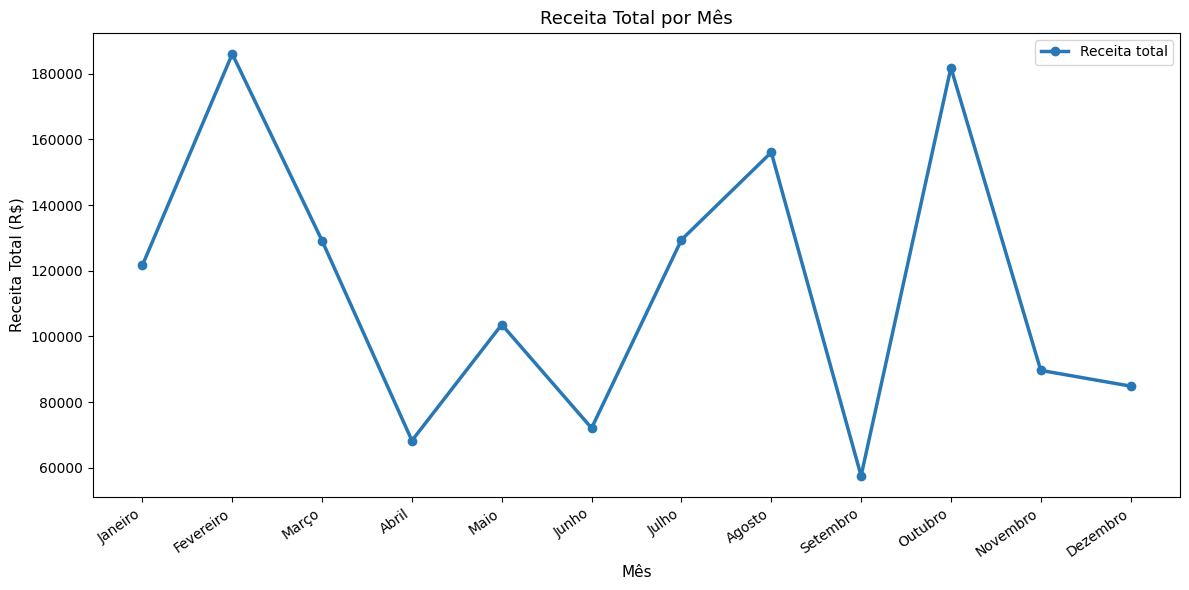

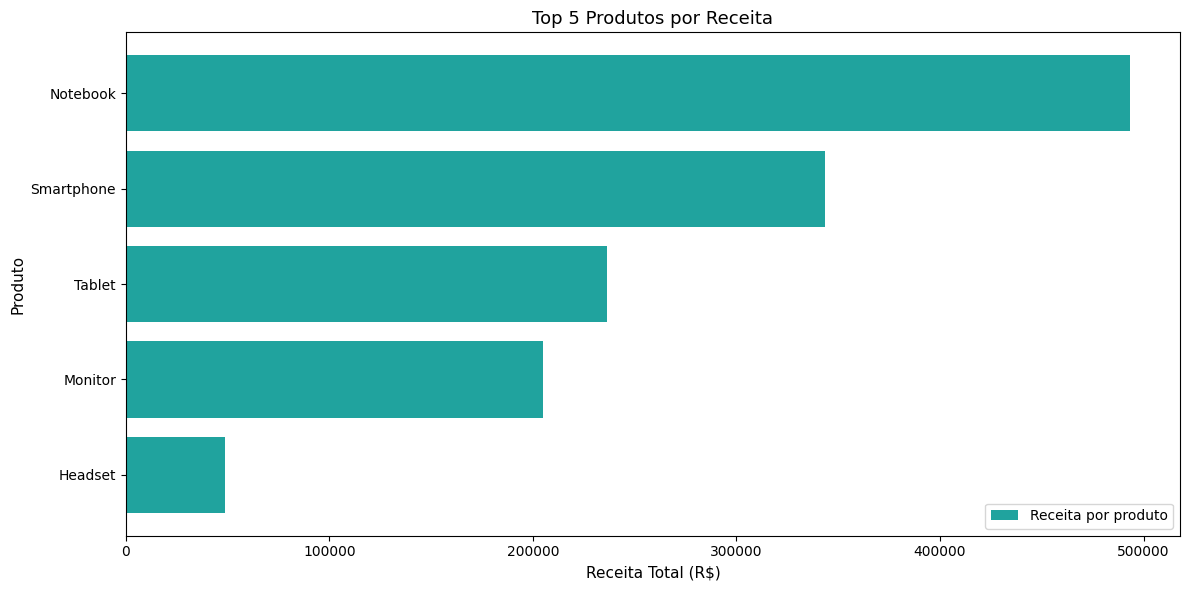

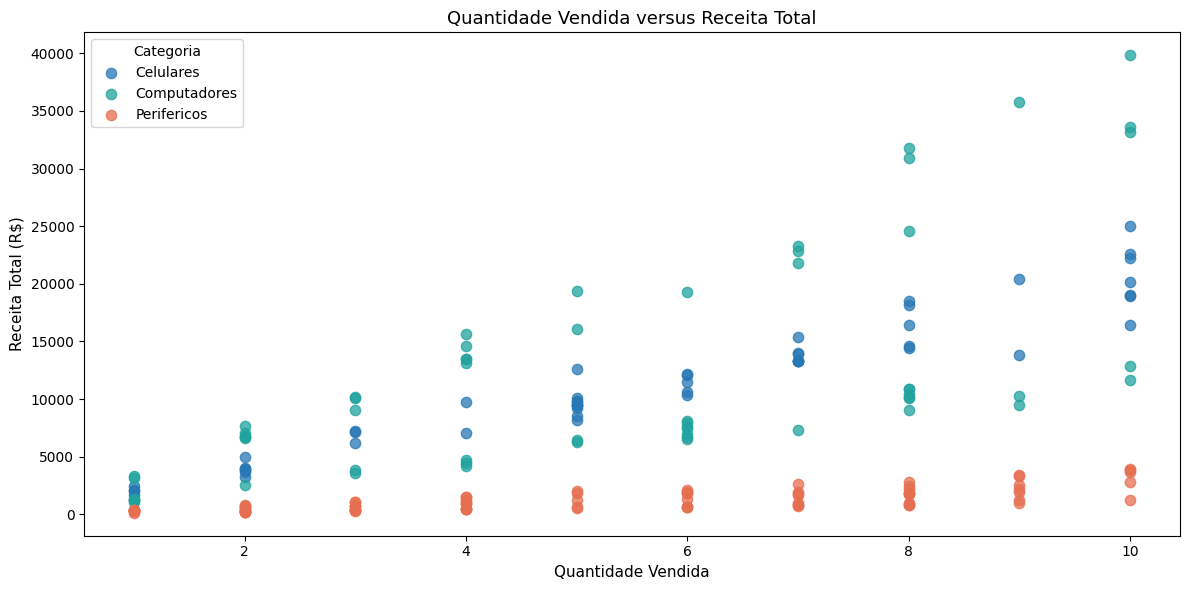

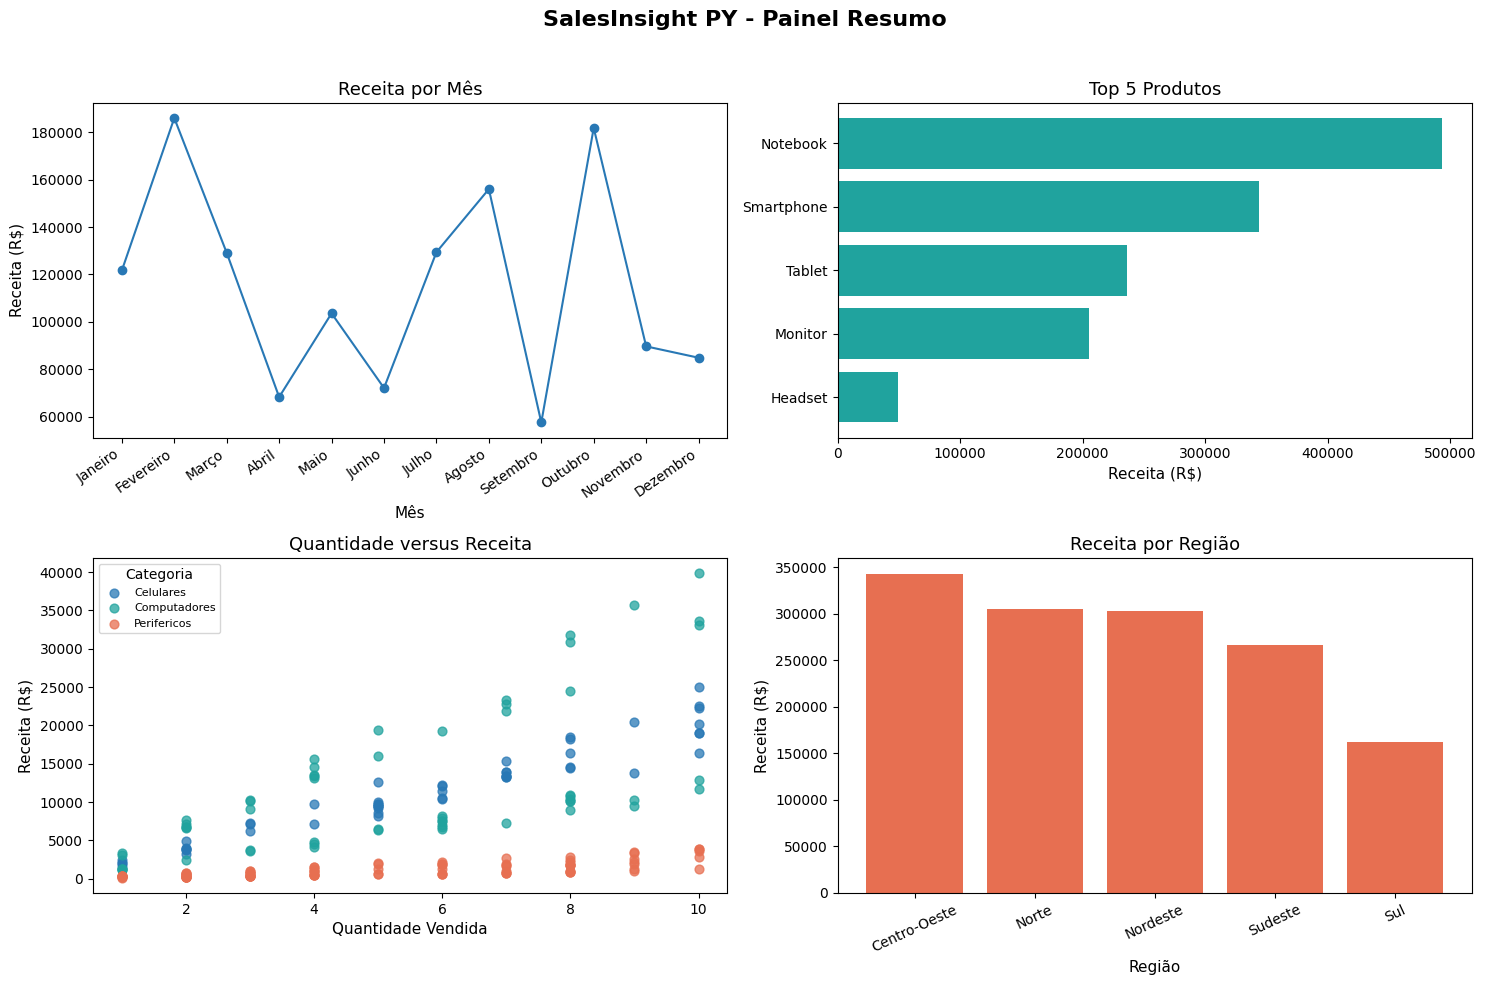


=== GRAFICOS GERADOS ===
outputs/graficos/receita_por_mes.png
outputs/graficos/top_produtos.png
outputs/graficos/quantidade_vs_receita.png
outputs/graficos/painel_resumo.png
CSV de métricas mensais gravado com sucesso.
CSV de segmentação de clientes gravado com sucesso.

JSON gravado e lido:
{
    "total_registros": 194.0,
    "receita_total": 1380210.31,
    "quantidade_total_vendida": 1035.0,
    "ticket_medio": 7114.49
}

Arquivos gerados:
- outputs/metricas_por_mes.csv
- outputs/segmentacao_clientes.csv
- outputs/estatisticas_gerais.json

=== RESUMO FINAL ===
Registros analisados: 194
Receita total: R$ 1380210.31
Quantidade total vendida: 1035

[CONCLUIDO] Fluxo finalizado com sucesso.


In [39]:

import os
import json
import pandas as pd
import matplotlib.pyplot as plt


def gerar_graficos(df_derivado, metricas):
    """Gera e salva os quatro gráficos do projeto."""

    os.makedirs("outputs/graficos", exist_ok=True)

    PALETA = {
        "azul": "#2878B5",
        "turquesa": "#20A39E",
        "coral": "#E76F51",
        "dourado": "#E9C46A",
        "roxo": "#8064A2",
        "verde": "#4C956C"
    }

    cores = list(PALETA.values())

    por_mes = metricas["por_mes"]
    top_produtos = metricas["top_produtos"]
    por_regiao = metricas["por_regiao"]

    nomes_meses = {
        1: "Janeiro", 2: "Fevereiro", 3: "Março",
        4: "Abril", 5: "Maio", 6: "Junho",
        7: "Julho", 8: "Agosto", 9: "Setembro",
        10: "Outubro", 11: "Novembro", 12: "Dezembro"
    }

    # Gráfico 1: receita por mês
    fig, ax = plt.subplots(figsize=(12, 6))

    ax.plot(
        por_mes["mes"],
        por_mes["receita_total"],
        color=PALETA["azul"],
        marker="o",
        linewidth=2.5,
        label="Receita total"
    )

    ax.set_title("Receita Total por Mês")
    ax.set_xlabel("Mês")
    ax.set_ylabel("Receita Total (R$)")
    ax.set_xticks(por_mes["mes"])
    ax.set_xticklabels(
        [nomes_meses[int(m)] for m in por_mes["mes"]],
        rotation=35,
        ha="right"
    )
    ax.legend()

    plt.tight_layout()
    plt.savefig(
        "outputs/graficos/receita_por_mes.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    # Gráfico 2: top 5 produtos
    fig, ax = plt.subplots(figsize=(12, 6))

    ax.barh(
        top_produtos["produto"],
        top_produtos["receita_total"],
        color=PALETA["turquesa"],
        label="Receita por produto"
    )

    ax.set_title("Top 5 Produtos por Receita")
    ax.set_xlabel("Receita Total (R$)")
    ax.set_ylabel("Produto")
    ax.invert_yaxis()
    ax.legend()

    plt.tight_layout()
    plt.savefig(
        "outputs/graficos/top_produtos.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    # Gráfico 3: quantidade versus receita
    fig, ax = plt.subplots(figsize=(12, 6))

    categorias = sorted(
        df_derivado["categoria"].dropna().unique()
    )

    for i, categoria in enumerate(categorias):
        dados = df_derivado[
            df_derivado["categoria"] == categoria
        ]

        ax.scatter(
            dados["quantidade"],
            dados["receita_total"],
            color=cores[i % len(cores)],
            label=categoria,
            alpha=0.75,
            s=55
        )

    ax.set_title("Quantidade Vendida versus Receita Total")
    ax.set_xlabel("Quantidade Vendida")
    ax.set_ylabel("Receita Total (R$)")
    ax.legend(title="Categoria")

    plt.tight_layout()
    plt.savefig(
        "outputs/graficos/quantidade_vs_receita.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    # Gráfico 4: painel resumo com subplots 2x2
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    axes[0, 0].plot(
        por_mes["mes"],
        por_mes["receita_total"],
        color=PALETA["azul"],
        marker="o"
    )
    axes[0, 0].set_title("Receita por Mês")
    axes[0, 0].set_xlabel("Mês")
    axes[0, 0].set_ylabel("Receita (R$)")
    axes[0, 0].set_xticks(por_mes["mes"])
    axes[0, 0].set_xticklabels(
        [nomes_meses[int(m)] for m in por_mes["mes"]],
        rotation=35,
        ha="right"
    )

    axes[0, 1].barh(
        top_produtos["produto"],
        top_produtos["receita_total"],
        color=PALETA["turquesa"]
    )
    axes[0, 1].set_title("Top 5 Produtos")
    axes[0, 1].set_xlabel("Receita (R$)")
    axes[0, 1].invert_yaxis()

    for i, categoria in enumerate(categorias):
        dados = df_derivado[
            df_derivado["categoria"] == categoria
        ]

        axes[1, 0].scatter(
            dados["quantidade"],
            dados["receita_total"],
            color=cores[i % len(cores)],
            label=categoria,
            alpha=0.75,
            s=40
        )

    axes[1, 0].set_title("Quantidade versus Receita")
    axes[1, 0].set_xlabel("Quantidade Vendida")
    axes[1, 0].set_ylabel("Receita (R$)")
    axes[1, 0].legend(title="Categoria", fontsize=8)

    axes[1, 1].bar(
        por_regiao["regiao"],
        por_regiao["receita_total"],
        color=PALETA["coral"]
    )
    axes[1, 1].set_title("Receita por Região")
    axes[1, 1].set_xlabel("Região")
    axes[1, 1].set_ylabel("Receita (R$)")
    axes[1, 1].tick_params(axis="x", rotation=25)

    fig.suptitle(
        "SalesInsight PY - Painel Resumo",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig(
        "outputs/graficos/painel_resumo.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    print("\n=== GRAFICOS GERADOS ===")
    print("outputs/graficos/receita_por_mes.png")
    print("outputs/graficos/top_produtos.png")
    print("outputs/graficos/quantidade_vs_receita.png")
    print("outputs/graficos/painel_resumo.png")


class AnalisadorDeVendas:
    """Organiza o fluxo de análise de vendas."""

    def __init__(self):
        self.df_bruto = None
        self.df_limpo = None
        self.df_derivado = None
        self.relatorio = None
        self.metricas = None
        self.clientes_segmentados = None
        self.estatisticas = None

    def carregar(self, caminho):
        """Carrega e inspeciona os dados brutos."""

        self.df_bruto = pd.read_csv(caminho)
        inspecionar_dados(self.df_bruto)

    def transformar(self):
        """Limpa os dados e cria as colunas derivadas."""

        self.df_limpo, self.relatorio = tratar_dados(
            self.df_bruto
        )

        self.df_derivado = criar_colunas_derivadas(
            self.df_limpo
        )

        # Aplicar as transformações reutilizáveis
        self.df_derivado = processar_coluna(
            self.df_derivado,
            "receita_total",
            lambda x: round(x / 1000, 2),
            nome_saida="receita_em_milhares"
        )

        self.df_derivado = processar_coluna(
            self.df_derivado,
            "quantidade",
            lambda q: (
                "Alto Volume" if q > 5 else "Baixo Volume"
            ),
            nome_saida="perfil_volume"
        )

        print("\n=== FUNCOES REUTILIZAVEIS ===")
        print(
            self.df_derivado[
                [
                    "receita_total",
                    "receita_em_milhares",
                    "quantidade",
                    "perfil_volume"
                ]
            ].head().to_string(index=False)
        )

    def analisar(self):
        """Calcula métricas e segmenta os clientes."""

        self.metricas = calcular_metricas(
            self.df_derivado
        )

        self.clientes_segmentados = segmentar_clientes(
            self.df_derivado
        )

        self.estatisticas = {
            "total_registros": len(self.df_derivado),
            "receita_total": self.df_derivado[
                "receita_total"
            ].sum(),
            "quantidade_total_vendida": self.df_derivado[
                "quantidade"
            ].sum(),
            "ticket_medio": self.df_derivado[
                "receita_total"
            ].mean()
        }

    def visualizar(self):
        """Gera e salva os gráficos."""

        gerar_graficos(
            self.df_derivado,
            self.metricas
        )

    def resumo(self):
        """Exporta os resultados e apresenta um resumo."""

        exportar_resultados(
            self.metricas,
            self.clientes_segmentados,
            self.estatisticas
        )

        print("\n=== RESUMO FINAL ===")
        print(
            f"Registros analisados: {len(self.df_derivado)}"
        )
        print(
            "Receita total: R$ "
            f"{self.estatisticas['receita_total']:.2f}"
        )
        print(
            "Quantidade total vendida: "
            f"{self.estatisticas['quantidade_total_vendida']}"
        )


def main():
    """Executa o fluxo completo do SalesInsight PY."""

    print("=" * 60)
    print("   SALESINSIGHT PY - Analise de Dados de Vendas")
    print("=" * 60)

    # Garantir a existência do dataset
    if not os.path.exists("vendas.csv"):
        gerar_dataset_vendas().to_csv(
            "vendas.csv",
            index=False
        )

    # Criar o analisador e executar as etapas na ordem correta
    analisador = AnalisadorDeVendas()

    analisador.carregar("vendas.csv")
    analisador.transformar()
    analisador.analisar()
    analisador.visualizar()
    analisador.resumo()

    print("\n[CONCLUIDO] Fluxo finalizado com sucesso.")

    return analisador


if __name__ == "__main__":
    analisador = main()
